# Monte Carlo
*Trajectories that stop early*

> A batch of projectiles flies until each one lands or leaves the field. They stop at different
> steps, so the live set thins out. eagle keeps a map of the live samples, recomputes it every few
> steps, and runs the whole loop as one replayed graph.

**Time:** ~5 min · **Runs on:** CPU (a GPU is picked up automatically and runs a larger batch) · **You need:** eagle, hawk, NumPy and matplotlib; read first: {doc}`06_compaction_and_reorder`

A Monte Carlo ensemble draws many launch conditions and follows each trajectory until it ends:
a landing, an escape, a collision. Here every projectile has its own speed and angle, feels
linear drag, and stops when it lands or crosses the far edge of the field. You will compose the
loop from `ActiveSet`, `compaction_body` and `repeat_while`, and then look at what `group=` changes. The projectile model and its
checks against the exact solution are on [hawk's Monte Carlo page](https://amasat01.github.io/hawk/content/vocabulary/12_monte_carlo_ensemble.html); this page is the orchestration around the kernel.

**Colab or Kaggle:** run this first cell (it installs the packages and downloads the helper files this notebook uses). Elsewhere it only checks the imports.

In [1]:
# Colab setup, generated by python -m raptor_docs.nb colab_setup (do not edit).
import os

try:
    import google.colab  # noqa: F401
    HOSTED = True  # a Colab runtime
except ImportError:
    HOSTED = "KAGGLE_KERNEL_RUN_TYPE" in os.environ  # a Kaggle kernel

if HOSTED:
    import importlib.metadata, pathlib, re, shutil, subprocess, sys, urllib.request

    gpu = bool(shutil.which("nvidia-smi")) and subprocess.run(["nvidia-smi", "-L"], capture_output=True).returncode == 0
    extra = ""
    if gpu:
        # the CUDA major the runtime already has: a CuPy that is installed, else torch's, else the driver's
        major = None
        for m in ("13", "12"):
            try:
                importlib.metadata.version(f"cupy-cuda{m}x")
                major = m
                break
            except importlib.metadata.PackageNotFoundError:
                pass
        if major is None:
            try:
                import torch
                major = "13" if str(torch.version.cuda).startswith("13") else None
            except ImportError:
                pass
        if major is None:
            smi = re.search(r"CUDA Version: (\d+)", subprocess.run(["nvidia-smi"], capture_output=True, text=True).stdout)
            major = "13" if smi and int(smi.group(1)) >= 13 else "12"
        extra = f"[cuda{major}]"
        print(f"GPU found: installing the {extra} extras to match this runtime.")
    pre = ["--pre"] if os.environ.get("RAPTOR_PRE") else []  # optional: test a release candidate
    ref = os.environ.get("RAPTOR_REF", "main")  # optional: fetch the helper files from this git ref
    if pre or "RAPTOR_REF" in os.environ:
        print(f"Pre-release test: installing with --pre, helper files from {ref}.")
    # our packages with --upgrade, so a runtime that kept an older release gets the current one
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "--upgrade", *pre, f"raptor-eagle{extra}", f"raptor-hawk{extra}"])
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "matplotlib"])
    base = os.environ.get("RAPTOR_RAW_BASE", "https://raw.githubusercontent.com")  # optional: a local mirror
    top = os.environ.get("RAPTOR_WORKDIR") or ("/kaggle/working" if "KAGGLE_KERNEL_RUN_TYPE" in os.environ else "/content")
    root = pathlib.Path(top) / "eagle"
    for rel in (
        "docs/content/_shared/anim.py",
        "docs/content/_shared/nb_helpers.py",
        "docs/content/_shared/themed_figure.py",
    ):
        (root / rel).parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(f"{base}/amasat01/eagle/{ref}/{rel}", root / rel)
    (root / "docs/content/userguide/tutorials").mkdir(parents=True, exist_ok=True)
    os.chdir(root / "docs/content/userguide/tutorials")
    if not gpu:
        print("Running on the CPU (no GPU in this runtime). For a GPU: " + ("Settings → Accelerator → GPU T4 x2." if "KAGGLE_KERNEL_RUN_TYPE" in os.environ else "Runtime → Change runtime type → T4 GPU."))

try:
    import eagle, hawk, matplotlib  # noqa: F401
except ImportError as err:
    raise ImportError(
        "eagle, hawk, matplotlib not found. Install with `pip install matplotlib raptor-eagle raptor-hawk`. For a GPU, add [cuda12] (or [cuda13]) to raptor-eagle and raptor-hawk."
    ) from err

In [2]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent.parent / "_shared"))
from nb_helpers import gpu_available, plot_style, to_numpy, xp_for

In [3]:
import numpy as np

DEVICE = "gpu" if gpu_available() else "cpu"
xp = xp_for(DEVICE)
n = 8192 if DEVICE == "gpu" else 512
print("running on", DEVICE, "with", n, "projectiles")

running on cpu with 512 projectiles


## The projectile's words

Say the vocabulary first. A projectile has a position and a velocity, written by every step; the drag, gravity, time step and field length are the same for all; and a `terminated` flag marks the samples that have landed or left. Declare them once as a `KernelKind`, with the guard that reads the map of live samples. The step below is written in these names.

In [4]:
from hawk import Mutable, Param, Scalar, Terminated
from hawk.ext import Guard, KernelKind


class Projectiles(KernelKind, slug="projectile_ensemble"):
    drag: Param
    g: Param
    dt: Param
    xmax: Param
    terminated: Terminated
    x: Mutable[Scalar]
    y: Mutable[Scalar]
    vx: Mutable[Scalar]
    vy: Mutable[Scalar]
    guard = Guard(active_set=True)      # a launch covers only the live samples

Projectiles

__main__.Projectiles

## The kernel: one step, and the condition that ends it

Units are SI: metres, metres per second, seconds. A sample's state is a position and a velocity.
The step is one semi-implicit (symplectic) Euler update with linear drag `k` = 0.1 1/s and
`dt` = 0.02 s, so `k * dt` = 0.002 and the step is stable. It is first order in `dt`; the check
below confirms that. `terminated` is the one statement that says when a sample is done: it is set
once the projectile is below the ground or past `xmax`, so a landing is seen one step late (the
overshoot is at most `dt * |vy|`, about 0.6 m here). From then on the sample's state no longer
changes.

The kernel is built with `Guard(active_set=True)`, as in {doc}`06_compaction_and_reorder`: it
reads a map of live samples, so a launch can cover only those.

In [5]:
import hawk
from hawk import Mutable, Param, Scalar, Terminated
from hawk.math import lor


def fly_step(drag, g, dt, xmax, terminated, x, y, vx, vy):
    vx = vx - dt * drag * vx
    vy = vy - dt * (g + drag * vy)
    x = x + dt * vx
    y = y + dt * vy
    terminated = lor(y < 0.0, x > xmax)


fly = hawk.kernel(fly_step, kind=Projectiles.kind, steps=1)      # `steps=` goes with the kernel, not with the vocabulary


In [6]:
import eagle

plan = eagle.deploy(fly)
G, K, XMAX = 9.81, 0.1, 40.0


def fresh(speed, angle):
    m = len(speed)
    state = dict(x=xp.zeros(m), y=xp.full(m, 1e-3),
                 vx=xp.asarray(speed * np.cos(angle)), vy=xp.asarray(speed * np.sin(angle)))
    done = xp.zeros(m, dtype=xp.bool_)
    return state, done, eagle.ActiveSet(done)


def bind(state, done, active, dt, xmax=XMAX):
    return plan.bind(drag=K, g=G, dt=dt, xmax=xmax, terminated=done, **state,
                     finished_count=xp.zeros(1, xp.uint32), **active.planes())

## Draw the ensemble

Speeds and angles are drawn at random, so landing times spread out: a flat shot lands within a
few steps, a lob takes many.

In [7]:
rng = np.random.default_rng(3)
speed = rng.uniform(8.0, 30.0, n)
angle = rng.uniform(0.15, 1.35, n)
DT = 0.02

## The loop, composed

`compaction_body` runs the step a few times (`every`), then recomputes the live-sample map on the
device, only when the finished counter moved. `repeat_while` turns that into one bounded loop that
stops when every sample is done. On a GPU the loop is one CUDA graph, built once and replayed, so
nothing is read back to the host between steps. On the CPU it runs as a plain loop.

In [8]:
from eagle import GraphPipeline, SkipGuard, compaction_body, repeat_while


def run_loop(speed, angle, every=4, max_steps=2000):
    state, done, active = fresh(speed, angle)
    counter = xp.zeros(1, xp.uint32)
    run = plan.bind(drag=K, g=G, dt=DT, xmax=XMAX, terminated=done, **state,
                    finished_count=counter, **active.planes())
    body = compaction_body(run.launch, active, every=every, finished=counter)
    loop = repeat_while(body, SkipGuard(counter, 0, xp.asarray([len(speed)], xp.uint32), 0),
                        -(-max_steps // every))
    if DEVICE == "gpu":
        GraphPipeline().add(loop).build().launch()
        xp.cuda.Device().synchronize()
    else:
        loop()
    return state, done, loop


state, done, loop = run_loop(speed, angle)
landed = int(to_numpy(done).sum())
print(f"{loop.iterations()} loop passes, {landed} of {n} samples ended")

65 loop passes, 512 of 512 samples ended


## A host loop, for the picture

The graph replays the loop without showing you the steps in between. To draw the trajectories
we step the same plan by hand and keep every position: after each step the map is recomputed on
the device and read back. That read-back is the cost the graph above avoids, so use it for
looking, not for running. The finished state is the same.

In [9]:
SHOWN = 48  # trajectories kept for the picture


def traced(speed, angle):
    state, done, active = fresh(speed, angle)
    run = bind(state, done, active, DT)
    active.compact()
    path = [tuple(to_numpy(state[k])[:SHOWN].copy() for k in "xy") + (to_numpy(done)[:SHOWN].copy(),)]
    live, covered = [len(speed)], [len(speed)]
    ended = np.full(len(speed), -1)
    for step in range(1, 2000):
        run.launch()
        active.compact()
        d = to_numpy(done)
        ended[(d) & (ended < 0)] = step
        live.append(len(speed) - int(d.sum()))
        covered.append(int(to_numpy(active.count)[0]))
        path.append(tuple(to_numpy(state[k])[:SHOWN].copy() for k in "xy") + (d[:SHOWN].copy(),))
        if live[-1] == 0:
            break
    return state, path, live, covered, ended


state_h, path, live, covered, ended = traced(speed, angle)
same = all(np.array_equal(to_numpy(state[k]), to_numpy(state_h[k])) for k in "xy")
steps = len(live) - 1
print(f"every projectile ended within {steps} steps; same final state as the graph loop: {same}")

every projectile ended within 260 steps; same final state as the graph loop: True


## What a launch covers, and what `group=` is for

The kernel reads one lane at a time, so `group=1` is the right set for it: a launch covers exactly
the live samples. `group=32` is for kernels that declare a group, such as a sum over the fastest
axis of a lane space, a commit that every lane of a warp makes together, or neighbour reads. It
keeps a whole group of 32 lanes while any member is live, and pays back in contiguous,
coalesced access, not in fewer lanes. eagle refuses a `group=32` set for this flat kernel.

What the group costs in lanes depends on lane order. Counts below for `group=32` are what a set
would cover, worked out from the step each sample ended at; the `group=1` line is the real map.

In [10]:
def lanes_per_step(ended, group):
    # lanes a set of this group would cover at each step: live groups times the group size
    pad = -len(ended) % group
    last = np.concatenate([ended, np.full(pad, -1)]).reshape(-1, group)
    last = np.where(last < 0, len(live), last).max(axis=1)  # a group lives until its last member ends
    return np.array([group * int((last > s).sum()) for s in range(len(live))])


lanes_32 = lanes_per_step(ended, 32)
print("lanes over the whole run:  group=1", sum(covered), "| group=32 (random order, would cover)",
      int(lanes_32.sum()), "| no compaction", n * steps)

lanes over the whole run:  group=1 55235 | group=32 (random order, would cover) 117408 | no compaction 133120


Draw order is arbitrary, so sort it. The no-drag flight time, `min(2 vy0 / g, xmax / vx0)`, is
a cheap guess at how long a sample lives. Samples that end together then share groups.

In [11]:
guess = np.minimum(2 * speed * np.sin(angle) / G, XMAX / (speed * np.cos(angle)))
order = np.argsort(guess)
_, _, _, _, ended_sorted = traced(speed[order], angle[order])
lanes_32_sorted = lanes_per_step(ended_sorted, 32)
print("group=32 after sorting by the flight-time guess (would cover):", int(lanes_32_sorted.sum()))

group=32 after sorting by the flight-time guess (would cover): 65216



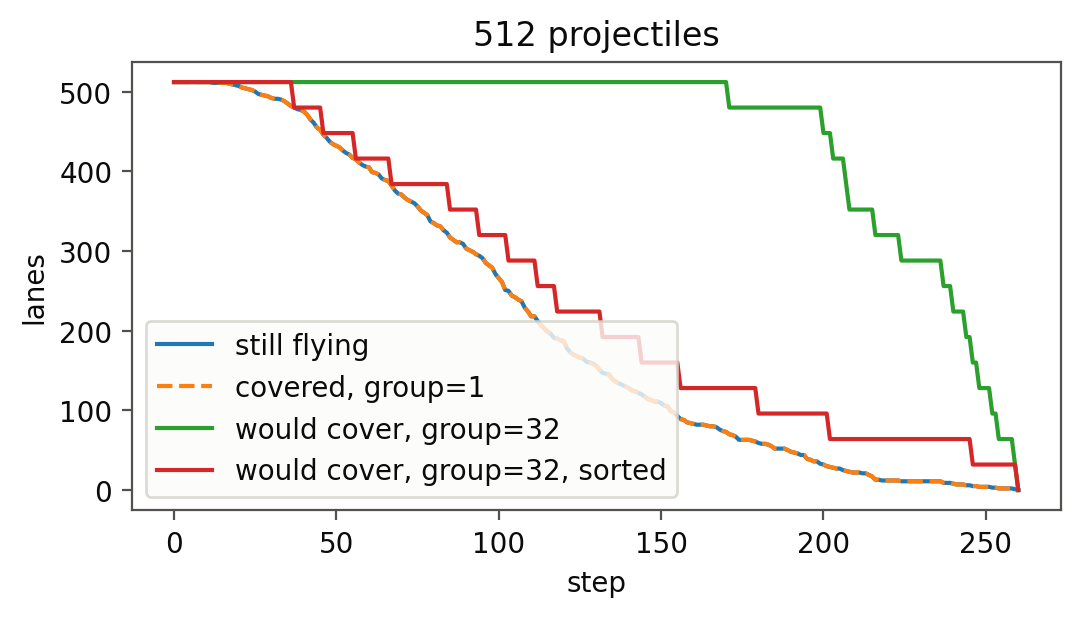
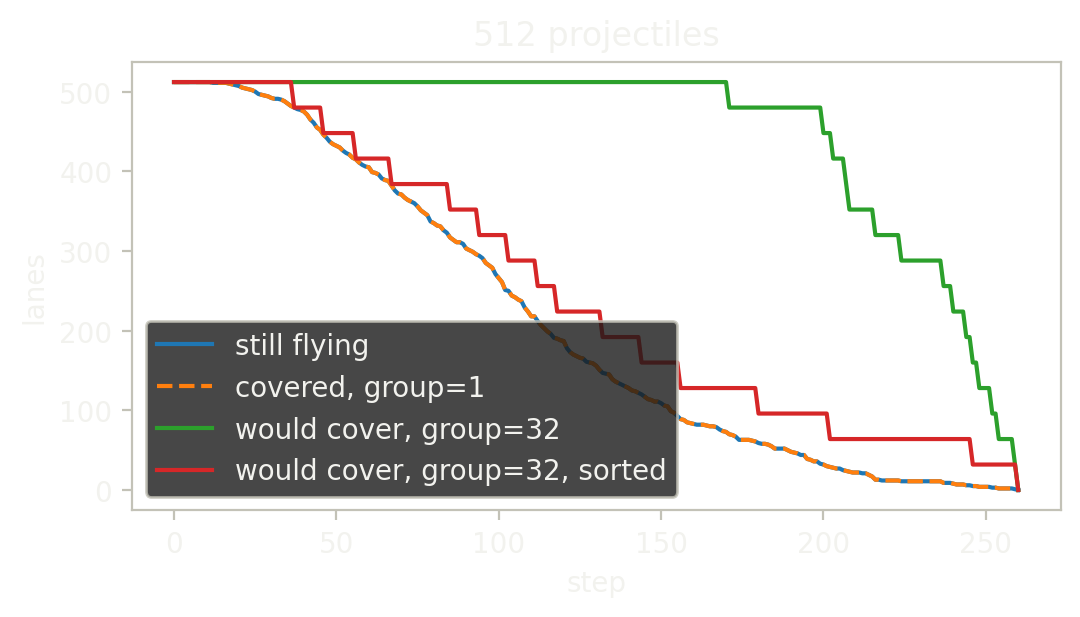

In [12]:
import matplotlib.pyplot as plt
from themed_figure import show

plot_style()
fig, ax = plt.subplots(figsize=(5.5, 3.2))
ax.plot(live, label="still flying")
ax.plot(covered, "--", label="covered, group=1")
ax.plot(lanes_32, label="would cover, group=32")
ax.plot(lanes_32_sorted, label="would cover, group=32, sorted")
ax.set_xlabel("step")
ax.set_ylabel("lanes")
ax.set_title(f"{n:,} projectiles")
ax.legend()
fig.tight_layout()
show()

Without compaction every step covers all `n` lanes until the last projectile lands. Whether
gathering the live samples pays on your device depends on the batch size and the cost of the
step: {doc}`06_compaction_and_reorder` has the card for each device.

## The animation

Trajectories on the left, the lanes a launch covers on the right. The same frames are written to
a GIF for the page (and to a short MP4 when `imageio-ffmpeg` is installed).

In [13]:
from anim import frame_of, write_anim
from themed_figure import DARK, LIGHT

pick = np.unique(np.linspace(0, len(path) - 1, min(len(path), 72)).astype(int))


def render(theme, k):
    pal = LIGHT if theme == "light" else DARK
    fig, (a, b) = plt.subplots(1, 2, figsize=(6.4, 2.9), dpi=60, facecolor=pal["bg"])
    for ax in (a, b):
        ax.set_facecolor(pal["bg"])
        for s in ax.spines.values():
            s.set_color(pal["rule"])
        ax.tick_params(colors=pal["sub"], labelsize=7)
    i = pick[k]
    for j in range(SHOWN):
        xs = [p[0][j] for p in path[: i + 1]]
        ys = [p[1][j] for p in path[: i + 1]]
        a.plot(xs, ys, lw=0.6, color=pal["us"], alpha=0.5)
        a.plot(xs[-1], ys[-1], "o", ms=2.5, color=pal["off"] if path[i][2][j] else pal["on"])
    a.set_xlim(0, 42)
    a.set_ylim(0, 30)
    a.set_xlabel("x (m)", color=pal["sub"], fontsize=8)
    a.set_ylabel("height (m)", color=pal["sub"], fontsize=8)
    b.plot(covered[: i + 1], color=pal["us"], lw=1.2, label="group=1")
    b.plot(lanes_32[: i + 1], "--", color=pal["on"], lw=1.2, label="group=32, would cover")
    b.set_xlim(0, len(path))
    b.set_ylim(0, n * 1.05)
    b.set_xlabel("step", color=pal["sub"], fontsize=8)
    b.set_ylabel("lanes covered", color=pal["sub"], fontsize=8)
    b.legend(fontsize=7, labelcolor=pal["ink"], facecolor=pal["bg"], edgecolor=pal["rule"], loc="upper right")
    fig.tight_layout()
    return frame_of(fig, pal["bg"])


for theme in ("light", "dark"):
    frames = [render(theme, k) for k in range(len(pick))]
    for name, size in write_anim(frames, f"monte_carlo_early_termination_{theme}").items():
        print(name, f"{size / 1e6:.2f} MB")

monte_carlo_early_termination_light.gif 0.75 MB


monte_carlo_early_termination_dark.gif 0.71 MB


```{image} ../../../_static/anim/monte_carlo_early_termination_light.gif
:class: only-light
:alt: Projectile trajectories end one by one while the lanes a launch covers fall
```
```{image} ../../../_static/anim/monte_carlo_early_termination_dark.gif
:class: only-dark
:alt: Projectile trajectories end one by one while the lanes a launch covers fall
```

## Try this

Narrow the draws to speeds in `(18, 22)` and angles in `(0.6, 0.8)` and re-run: the projectiles
end within about 50 steps of each other, and the gap between the `group=1` and `group=32` totals
shrinks.

## Next

- {doc}`06_compaction_and_reorder`: when gathering the live samples pays, device by device.
- {doc}`04_multi_kernel_workflow`: the same loop with several kernels sharing one set.
- {doc}`../../modules/filtering/scan_and_compaction`: `ActiveSet` and `group=` in the reference.